In [5]:
# Logistic regression on the Adult dataset
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, KFold
from preprocessing import load_adult, onehot

In [10]:
def train_logistic_regression(X_train, y_train):
    param_grid = {"C": [0.01, 0.1, 1, 10, 100]}
    kfold = KFold(n_splits=5, shuffle=True, random_state=42)
    grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=kfold, scoring='accuracy', return_train_score=True)
    grid.fit(X_train, y_train)
    return grid

if __name__ == "__main__":
    train, test = load_adult()
    y_train, y_test = train["income"], test["income"]
    X_train, X_test = onehot(train, test)

    grid = train_logistic_regression(X_train, y_train)
    # test once after C is chosen
    y_pred = grid.predict(X_test)

    train_acc = grid.cv_results_["mean_train_score"][grid.best_index_]
    test_acc = accuracy_score(y_test, y_pred)

    print(f"Chosen C:              {grid.best_params_['C']}")
    print(f"Training accuracy:     {train_acc:.1%}")
    print(f"Validation accuracy:   {grid.best_score_:.1%}")
    print(f"Test accuracy:         {test_acc:.1%}")
    print(f"Always guessing <=50K: {1 - y_test.mean():.1%}")

Chosen C:              1
Training accuracy:     84.7%
Validation accuracy:   84.6%
Test accuracy:         84.7%
Always guessing <=50K: 76.4%


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

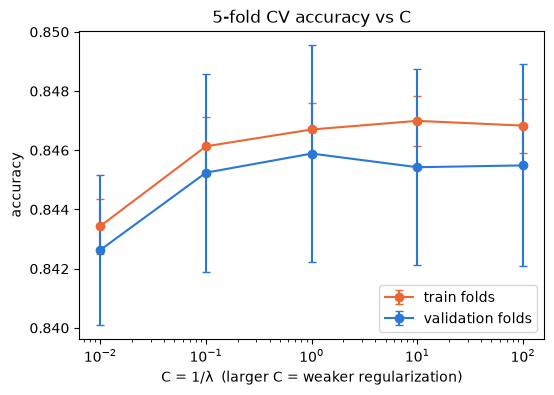

In [11]:
r = grid.cv_results_
C = r["param_C"].astype(float)

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(C, r["mean_train_score"], yerr=r["std_train_score"], marker="o", capsize=3, color="#eb6834", label="train folds")
ax.errorbar(C, r["mean_test_score"], yerr=r["std_test_score"], marker="o", capsize=3, color="#2a78d6", label="validation folds")
ax.set_xscale("log")
ax.set_xlabel("C = 1/λ  (larger C = weaker regularization)")
ax.set_ylabel("accuracy")
ax.set_title("5-fold CV accuracy vs C")
ax.legend()
plt.show()

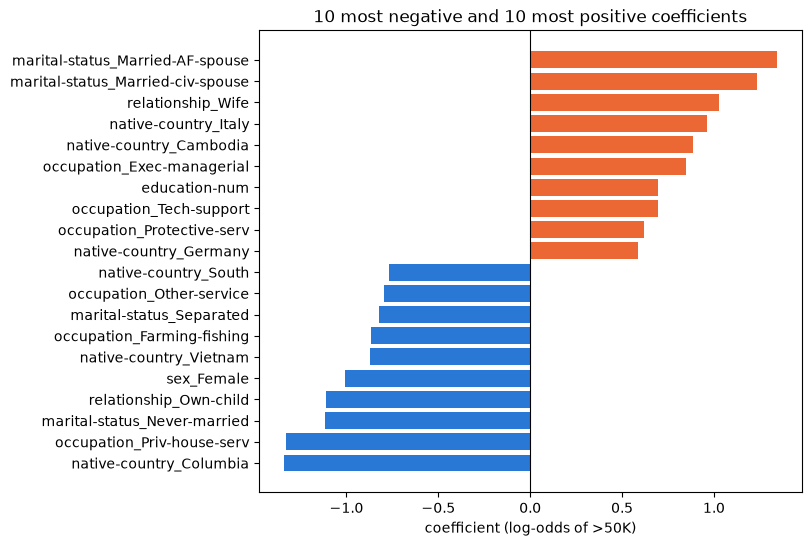

In [12]:
coef = pd.Series(grid.best_estimator_.coef_[0], index=X_train.columns).sort_values()
top = pd.concat([coef.head(10), coef.tail(10)])

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=np.where(top > 0, "#eb6834", "#2a78d6"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coefficient (log-odds of >50K)")
ax.set_title("10 most negative and 10 most positive coefficients")
plt.show()